In [ ]:
"""
Let's see if we can fit and extract parameters from our transients
"""

In [1]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import scipy.ndimage as snm

import plot_time_series as pts
import precision_recall as pr
import importlib

# importlib.reload(plot_time_series)
import gc  # garbage collector
import glob  # i don't know if there is a better way to do this but this was the

# internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os
import implantation_functions as imp
from scipy.signal import find_peaks
from scipy import optimize

In [45]:
df_lessthan13 = pd.read_csv(
    "/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/df_lessthan13"
)

In [58]:
len(df_lessthan13[df_lessthan13["snr_min"] < -11])

49

In [62]:
df_lessthan13[df_lessthan13["snr_min"] < -7]

,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant,sobel_ratio,snr_center,snr_max,snr_min
403,403,23,23,68,68,ztf_20221020157697_000640_zi_c16_x_0011.,neg,406.285714,733.190476,21.0,2,9.844989,-7.292497,0.247652,-7.776056
532,532,152,152,295,295,ztf_20221020157697_000640_zi_c16_x_0011.,both,406.285714,733.190476,21.0,2,9.844989,-7.292497,0.247652,-7.776056
694,694,46,46,227,227,ztf_20221020294271_000449_zr_c13_x_0016.,neg,313.192308,64.269231,26.0,2,12.834335,-2.021621,1.652752,-8.806954
716,716,68,68,256,256,ztf_20221020294271_000449_zr_c13_x_0016.,neg,769.379310,64.724138,29.0,2,17.119549,0.469652,2.700558,-7.891764
815,815,167,167,394,394,ztf_20221020294271_000449_zr_c13_x_0016.,neg,2773.771429,64.342857,35.0,2,18.014400,-9.775841,-1.345555,-9.775841
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
606804,607034,84,84,1089,1089,ztf_20221020141806_000686_zi_c16_x_0007.,neg,753.628571,713.685714,70.0,4,16.516829,-0.286381,0.974344,-10.551552
606805,607035,85,85,1090,1090,ztf_20221020141806_000686_zi_c16_x_0007.,neg,754.166667,721.083333,12.0,4,16.516829,-1.376337,0.968844,-10.491991
606942,607172,222,222,1595,1595,ztf_20221020141806_000686_zi_c16_x_0007.,both,737.000000,723.058824,17.0,4,16.960234,2.138895,2.138895,-8.908813
606943,607173,223,223,1606,1606,ztf_20221020141806_000686_zi_c16_x_0007.,both,754.166667,721.083333,12.0,4,16.516829,-1.376337,0.968844,-10.491991


In [5]:
tot = rff.get_tot(df_lessthan13, 1)

In [26]:
df_lessthan8[226802:226803]
# df_lessthan8[693:695]

,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant,sobel_ratio,snr_center,snr_max,snr_min
226802,226822,396,396,705,705,ztf_20221020294271_000449_zr_c13_x_0029.,both,2500.25,2537.75,12.0,4,9.517475,-7.739456,-0.385236,-9.079088


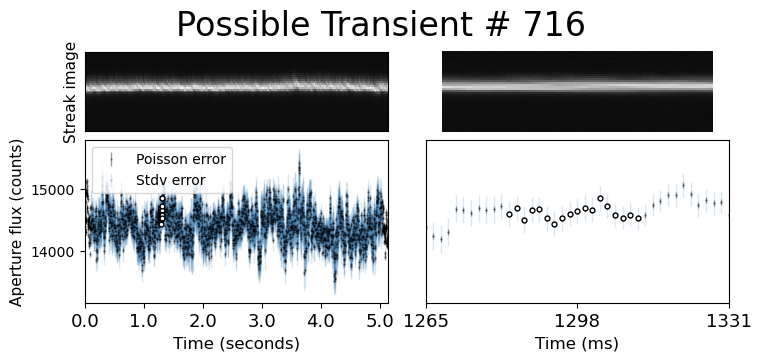

In [4]:
rff.plot_time_series_again_aperture(df_lessthan13, 716, "1020", 8)

In [7]:
file = (
    "/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c03_x_0029.fits.fz"
)
hdul = fits.open(file)
file1_array = hdul[1].data

In [8]:
file2 = (
    "/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020138241_000686_zi_c03_x_0029.fits.fz"
)
hdul2 = fits.open(file2)
file1_array2 = hdul2[1].data

norm2 = (file1_array2 - np.min(file1_array2)) / (
    np.max(file1_array2) - np.min(file1_array2)
)  # norm

In [ ]:
plt.imshow

In [39]:
np.max(imp_pos)

1.0

In [9]:
imp_pos = imp.implant_transient_full_image(
    file1_array2, streak_x_val=968, center_value_y=1000, intensity=1.3, sigma=5
)

[968, 969, 970, 967]


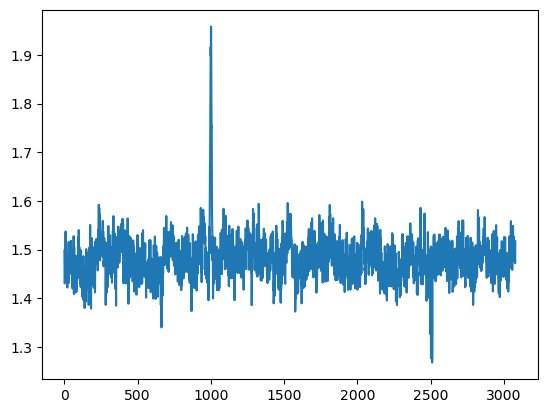

In [10]:
tot = rff.get_tot_streak(imp_pos, 968)
plt.plot(tot)

In [40]:
plot_time_series_zoom_implant(imp_pos, 968, 1000)

NameError: name 'plot_time_series_zoom_implant' is not defined

In [46]:
?rff.get_tot_streak

Signature: rff.get_tot_streak(image, col, tracking=True, half_aperture=2)
Docstring:     
File:      ~/review_findings_functions.py
Type:      function

In [42]:
# function that takes  xcoord, ycoord, size
# makes tot
# fits to gaussian
?imp.gaussian_event

Signature: imp.gaussian_event(ys, M, sig, A, original_values)
Docstring:
ys should be the array of y values
#m is the center y value
#sig is the standard deviation
#original_values is the original brightness (for each y value)
#A is the maximum brightening. A-1 is in the code bc of that additional 1 later
#return original_values * ((A-1) * (np.exp(-np.power(ys - M, 2.) / (2 * np.power(sig, 2.)))) + 1)
File:      ~/implantation_functions.py
Type:      function

In [11]:
# i should cut it to a relevant range probably too
# ys should not be part of the guess i don't think
tot_short = tot[M_guess - 20 : M_guess + 20]
ys = np.linspace(M_guess - 20, M_guess + 20, 41)
result = optimize.minimize(function_to_minimize(arguments), initial_guess)

NameError: name 'arguments' is not defined

In [1]:
result

NameError: name 'result' is not defined

In [12]:
def gaussian_event_streak_val(ys, M, sig, A, streak_val):
    """ys should be the array of y values
    #m is the center y value
    #sig is the standard deviation
    #original_values is the original brightness (for each y value)
    #A is the maximum brightening. A-1 is in the code bc of that additional 1 later
    #return original_values * ((A-1) * (np.exp(-np.power(ys - M, 2.) / (2 * np.power(sig, 2.)))) + 1)
    """
    original_values = np.full(len(ys), streak_val)
    return original_values * (
        (A - 1) * (np.exp(-np.power(ys - M, 2.0) / (2 * np.power(sig, 2.0)))) + 1
    )

In [13]:
# Define the objective function
def function_to_minimize(params, x, ys):
    # Unpack parameters
    M, sig, A, streak_val = params

    # Compute the model's output
    model_output = gaussian_event_streak_val(ys, M, sig, A, streak_val)

    # Calculate the residuals between x and model_output
    residuals = np.abs(x - model_output)

    # Return an aggregated value (e.g., sum of residuals)
    return np.sum(residuals)  # this is L1, could do difference of squares

In [14]:
def fit_params(M_guess, sig_guess, A_guess, tot):
    """
    returns:
    print("Optimized M:", optimized_M)
    print("Optimized sig:", optimized_sig)
    print("Optimized A:", optimized_A)
    print("Optimized original_values:", optimized_streak_val)
    print("Minimum value:", result.fun)
    """
    # Fixed arrays for x and ys
    x = tot[M_guess - 60 : M_guess + 61]
    ys = np.linspace(M_guess - 60, M_guess + 60, 121)

    streak_val_guess = np.mean(
        np.append(tot[M_guess - 60 : M_guess - 10], tot[M_guess + 10 : M_guess + 61])
    )

    # Initial guesses for M, sig, A, and original_values
    initial_guess = [
        M_guess,
        sig_guess,
        A_guess,
        streak_val_guess,
    ]  # Replace with your actual initial guesses

    # Minimization
    result = optimize.minimize(function_to_minimize, initial_guess, args=(x, ys))

    # Extract optimized parameters
    optimized_M = result.x[0]
    optimized_sig = result.x[1]
    optimized_A = result.x[2]
    optimized_streak_val = result.x[3]
    min_val = result.fun
    return optimized_M, optimized_sig, optimized_A, optimized_streak_val, min_val

In [19]:
M_guess = 1000
sig_guess = 5
A_guess = 1.3


# Fixed arrays for x and ys
x = tot[M_guess - 60 : M_guess + 61]
ys = np.linspace(M_guess - 60, M_guess + 60, 121)

streak_val_guess = np.mean(
    np.append(tot[M_guess - 60 : M_guess - 10], tot[M_guess + 10 : M_guess + 61])
)

# Initial guesses for M, sig, A, and original_values
initial_guess = [
    M_guess,
    sig_guess,
    A_guess,
    streak_val_guess,
]  # Replace with your actual initial guesses

# Minimization
result = optimize.minimize(function_to_minimize, initial_guess, args=(x, ys))

# Extract optimized parameters
optimized_M = result.x[0]
optimized_sig = result.x[1]
optimized_A = result.x[2]
optimized_streak_val = result.x[3]

print("Optimized M:", optimized_M)
print("Optimized sig:", optimized_sig)
print("Optimized A:", optimized_A)
print("Optimized original_values:", optimized_streak_val)
print("Minimum value:", result.fun)

Optimized M: 1000.4120655914236
Optimized sig: 4.508778422894392
Optimized A: 1.3214895416032062
Optimized original_values: 1.466990213329001
Minimum value: 3.6395661009490876


In [15]:
np.append(tot[M_guess - 60 : M_guess - 10], tot[M_guess + 10 : M_guess + 61])

array([1.48505688, 1.45913613, 1.45955348, 1.5328517 , 1.56169116,
       1.51438916, 1.51779962, 1.55157363, 1.5817591 , 1.5154655 ,
       1.52344096, 1.54425383, 1.54681647, 1.56741261, 1.55259705,
       1.54289567, 1.51277864, 1.51526701, 1.55345416, 1.51949453,
       1.51607084, 1.51640773, 1.52714443, 1.51833677, 1.44739819,
       1.49540591, 1.50377619, 1.47790921, 1.44054258, 1.46310806,
       1.47967386, 1.45837152, 1.46351039, 1.44880807, 1.45145488,
       1.45192802, 1.43210864, 1.45443058, 1.47696924, 1.45422494,
       1.4945811 , 1.48391461, 1.4671917 , 1.43329203, 1.39579809,
       1.46824753, 1.47932041, 1.44747877, 1.4555918 , 1.54639125,
       1.53169644, 1.47797179, 1.48670793, 1.52748466, 1.4491924 ,
       1.3995415 , 1.44376945, 1.47795558, 1.45185494, 1.43571997,
       1.44141233, 1.46218634, 1.43001091, 1.43668127, 1.47749853,
       1.48993731, 1.46306252, 1.48833001, 1.51231885, 1.52438974,
       1.4733156 , 1.44390583, 1.45536947, 1.44051468, 1.48646

In [44]:
4.508778422894392 * (10000 / 3080)

14.63889098342335

In [16]:
M_guess = 1000
sig_guess = 5
A_guess = 1.3
fit_params(M_guess, sig_guess, A_guess, tot)

(1000.4120655914236,
 4.508778422894392,
 1.3214895416032062,
 1.466990213329001,
 3.6395661009490876)

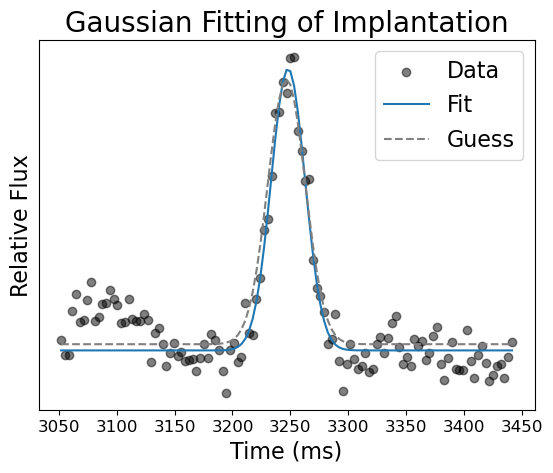

In [38]:
plt.scatter(ys * 10000 / 3080, x, label="Data", color="black", alpha=0.5)
plt.plot(
    ys * 10000 / 3080,
    gaussian_event_streak_val(
        ys, optimized_M, optimized_sig, optimized_A, optimized_streak_val
    ),
    label="Fit",
)
plt.plot(
    ys * 10000 / 3080,
    gaussian_event_streak_val(ys, M_guess, sig_guess, A_guess, streak_val_guess),
    label="Guess",
    color="grey",
    ls="--",
)
plt.xlabel("Time (ms)", fontsize=16)
plt.ylabel("Relative Flux", fontsize=16)
plt.yticks([])
plt.xticks(fontsize=12)
plt.title("Gaussian Fitting of Implantation", fontsize=20)
plt.legend(fontsize=16)

In [65]:
imp_neg = imp.implant_transient_full_image(
    file1_array2, streak_x_val=968, center_value_y=1000, intensity=0.8, sigma=5
)

[968, 969, 970, 967]


In [66]:
M_guess = 1000
sig_guess = 5
A_guess = 1.3


# Fixed arrays for x and ys
tot = tot = rff.get_tot_streak(imp_neg, 968)
x = tot[M_guess - 60 : M_guess + 61]
ys = np.linspace(M_guess - 60, M_guess + 60, 121)

streak_val_guess = np.mean(x)

# Initial guesses for M, sig, A, and original_values
initial_guess = [
    M_guess,
    sig_guess,
    A_guess,
    streak_val_guess,
]  # Replace with your actual initial guesses

# Minimization
result = optimize.minimize(function_to_minimize, initial_guess, args=(x, ys))

# Extract optimized parameters
optimized_M = result.x[0]
optimized_sig = result.x[1]
optimized_A = result.x[2]
optimized_streak_val = result.x[3]

print("Optimized M:", optimized_M)
print("Optimized sig:", optimized_sig)
print("Optimized A:", optimized_A)
print("Optimized original_values:", optimized_streak_val)
print("Minimum value:", result.fun)

Optimized M: 999.3278296429543
Optimized sig: 5.664817853146744
Optimized A: 0.8186586903549963
Optimized original_values: 1.4687273260187705
Minimum value: 3.5152825828796166


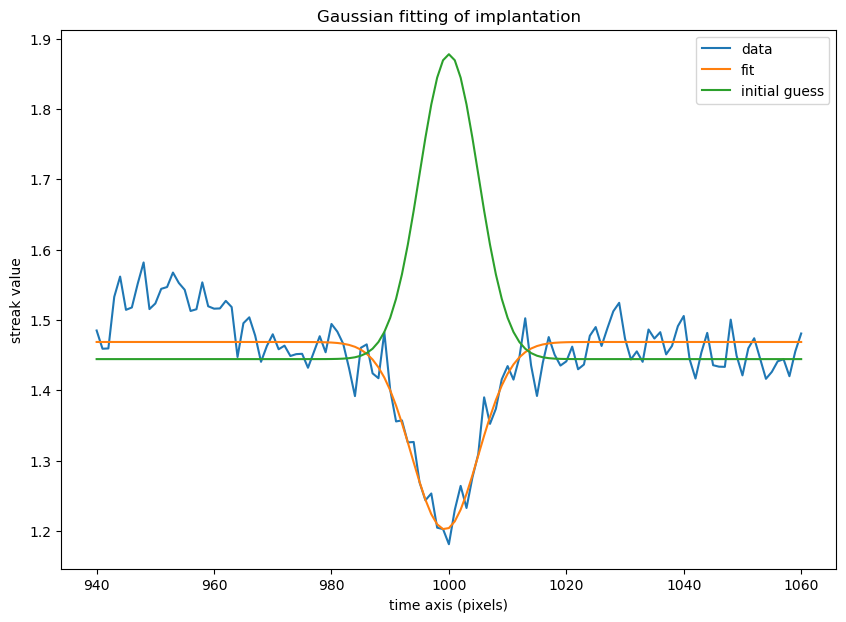

In [67]:
plt.plot(ys, x, label="data")
plt.plot(
    ys,
    gaussian_event_streak_val(
        ys, optimized_M, optimized_sig, optimized_A, optimized_streak_val
    ),
    label="fit",
)
plt.plot(
    ys,
    gaussian_event_streak_val(ys, M_guess, sig_guess, A_guess, streak_val_guess),
    label="initial guess",
)
plt.xlabel("time axis (pixels)")
plt.ylabel("streak value")
plt.title("Gaussian fitting of implantation")
plt.legend()

In [68]:
imp_smoll = imp.implant_transient_full_image(
    file1_array2, streak_x_val=968, center_value_y=1000, intensity=1.01, sigma=5
)

[968, 969, 970, 967]


Optimized M: 1000.1616373553186
Optimized sig: 4.945759851763919
Optimized A: 1.017973488454815
Optimized original_values: 1.4630645743232666
Minimum value: 3.752042863763908


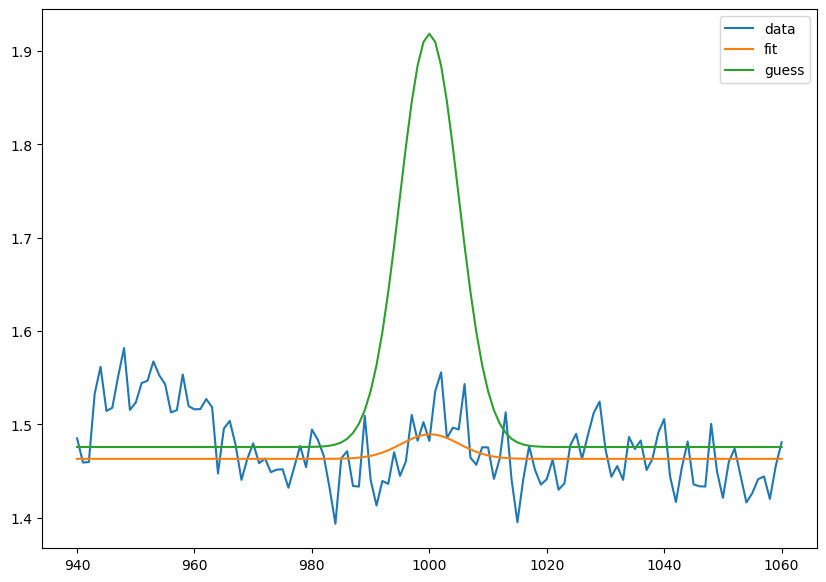

In [70]:
M_guess = 1000
sig_guess = 5
A_guess = 1.3


# Fixed arrays for x and ys
tot = tot = rff.get_tot_streak(imp_smoll, 968)
x = tot[M_guess - 60 : M_guess + 61]
ys = np.linspace(M_guess - 60, M_guess + 60, 121)

streak_val_guess = np.mean(x)

# Initial guesses for M, sig, A, and original_values
initial_guess = [
    M_guess,
    sig_guess,
    A_guess,
    streak_val_guess,
]  # Replace with your actual initial guesses

# Minimization
result = optimize.minimize(function_to_minimize, initial_guess, args=(x, ys))

# Extract optimized parameters
optimized_M = result.x[0]
optimized_sig = result.x[1]
optimized_A = result.x[2]
optimized_streak_val = result.x[3]

print("Optimized M:", optimized_M)
print("Optimized sig:", optimized_sig)
print("Optimized A:", optimized_A)
print("Optimized original_values:", optimized_streak_val)
print("Minimum value:", result.fun)
plt.plot(ys, x, label="data")
plt.plot(
    ys,
    gaussian_event_streak_val(
        ys, optimized_M, optimized_sig, optimized_A, optimized_streak_val
    ),
    label="fit",
)
plt.plot(
    ys,
    gaussian_event_streak_val(ys, M_guess, sig_guess, A_guess, streak_val_guess),
    label="guess",
)

plt.legend()

In [70]:
df_lessthan13.iloc[716]

Unnamed: 0.4                                           716
Unnamed: 0.3                                            68
Unnamed: 0.2                                            68
Unnamed: 0.1                                           256
Unnamed: 0                                             256
filename          ztf_20221020294271_000449_zr_c13_x_0016.
type                                                   neg
row_from_nn                                      769.37931
col_from_nn                                      64.724138
detection_size                                        29.0
quadrant                                                 2
sobel_ratio                                      17.119549
snr_center                                        0.469652
snr_max                                           2.700558
snr_min                                          -7.891764
Name: 716, dtype: object

In [ ]:
df_lessthan13, 716, "1020", 8

In [73]:
?rff.get_tot

Signature: rff.get_tot(df, index, direcname='1020', half_aperture=2, tracking=True)
Docstring:
returns tot, maxcols: an array that is the flux of the star streak
given an aperture that is halfaperture*2+1
and if tracking=true, tracks when the streak posittion fluctuates
oif tracking==false, goes based on average center of streak
File:      ~/review_findings_functions.py
Type:      function

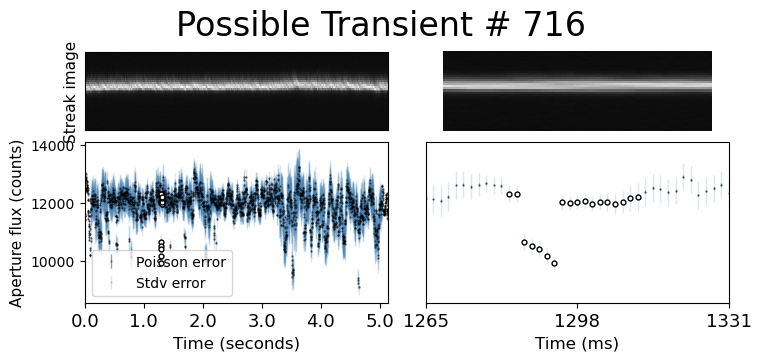

In [79]:
rff.plot_time_series_again_aperture(df_lessthan13, 716, "1020", 2)

In [86]:
df = df_lessthan13
index = 716
direcname = "1020"
fname = df.loc[index]["filename"] + "fits.fz"
row = (
    int(df.loc[index]["row_from_nn"]) + 10
)  # we add 10 here bc that's the cnn offset of returned values
col = int(df.loc[index]["col_from_nn"]) + 10
quad = int(df.loc[index]["quadrant"])
column = int(col)

fpath = (
    "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
    + direcname
    + "_minus_extras/"
)
path = fpath + fname
hdul = fits.open(path)
# print(path)
file1_array = hdul[quad].data
# norm = (file1_array-np.min(file1_array))/(np.max(file1_array)-np.min(file1_array)) #norm
image = file1_array

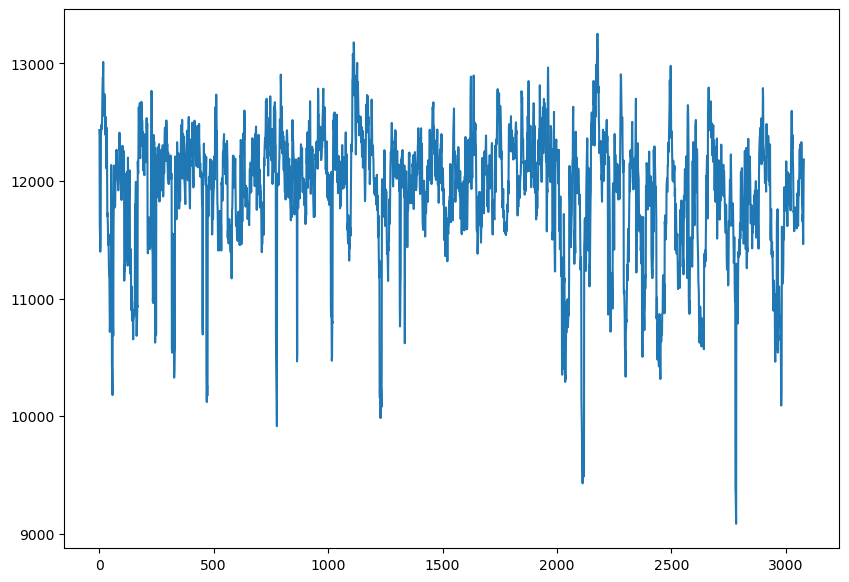

In [89]:
tot_streak = rff.get_tot_streak(image, col)
plt.plot(tot_streak)

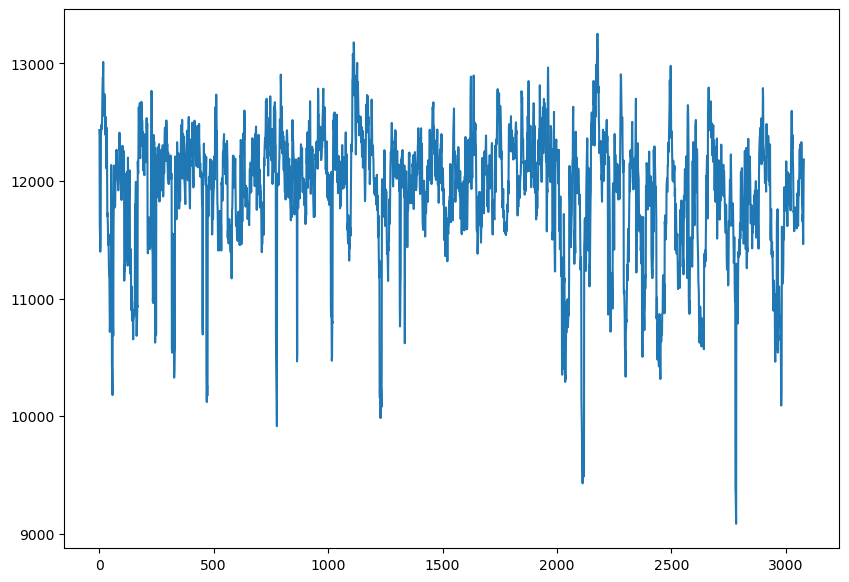

In [81]:
tot, maxcols = rff.get_tot(df_lessthan13, 716, "1020", 2)
plt.plot(tot)

In [95]:
tot[int(M_guess) - 60 : int(M_guess) + 61]

()

In [97]:
tot[30:50]

()

In [98]:
rff.get_tot(df_lessthan13, 716, "1020", 2)

(array([12432.94238281, 12385.58007812, 11621.98339844, ...,
        11707.38378906, 12083.29394531, 12182.71484375]),
 array([76., 76., 75., ..., 76., 76., 76.]))

In [104]:
?rff.get_stdvs

Signature: rff.get_stdvs(tot, do_all=True, df=None, index=None)
Docstring:
takes tot
do_all: if true, calculates the stdv for every point
if false, calculates the stdv around the detection
if do_all=false, must include df and index
File:      ~/review_findings_functions.py
Type:      function

In [108]:
df.loc[index]["snr_center"] * rff.get_stdvs(tot, do_all=False, df=df, index=index)

118.83520793171736

In [111]:
(df.loc[index]["snr_center"]) * streak_val_guess

5717.747970577882

In [116]:
np.min(tot)

9083.3818359375

0.9881138142333253
Optimized M: 774.6519227706602
Optimized sig: 1.8024831822299825
Optimized A: 0.8158493415838449
Optimized original_values: 12260.803924157286
Minimum value: 214.02619166442142


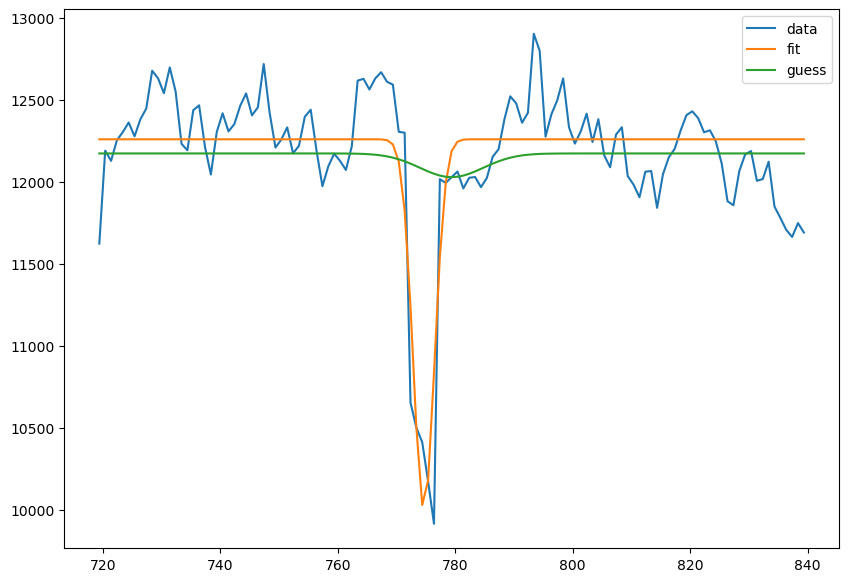

In [119]:
index = 716

M_guess = df.loc[index]["row_from_nn"] + 10
sig_guess = np.sqrt(df.loc[index]["detection_size"])
# if np.abs(df.loc[index]['snr_max'])>np.abs(df.loc[index]['snr_min']):
#     A_guess = df.loc[index]['snr_max']
# else:
#     A_guess = df.loc[index]['snr_min']


# Fixed arrays for x and ys
tot, maxcols = rff.get_tot(df_lessthan13, 716, "1020", 2)
x = tot[int(M_guess) - 60 : int(M_guess) + 61]
ys = np.linspace(M_guess - 60, M_guess + 60, 121)

streak_val_guess = np.mean(x)

A_guess = tot[int(M_guess)] / streak_val_guess
print(A_guess)

# Initial guesses for M, sig, A, and original_values
initial_guess = [
    M_guess,
    sig_guess,
    A_guess,
    streak_val_guess,
]  # Replace with your actual initial guesses

# Minimization
result = optimize.minimize(function_to_minimize, initial_guess, args=(x, ys))

# Extract optimized parameters
optimized_M = result.x[0]
optimized_sig = result.x[1]
optimized_A = result.x[2]
optimized_streak_val = result.x[3]

print("Optimized M:", optimized_M)
print("Optimized sig:", optimized_sig)
print("Optimized A:", optimized_A)
print("Optimized original_values:", optimized_streak_val)
print("Minimum value:", result.fun)
plt.plot(ys, x, label="data")
plt.plot(
    ys,
    gaussian_event_mean(
        ys, optimized_M, optimized_sig, optimized_A, optimized_streak_val
    ),
    label="fit",
)
plt.plot(
    ys,
    gaussian_event_mean(ys, M_guess, sig_guess, A_guess, streak_val_guess),
    label="guess",
)

plt.legend()

In [ ]:
#so let's do it for 1000
params_M = 
params_sig = 
params_A = 



In [120]:
transient_info_list = [1, [2, 3]]

In [123]:
transient_info_list.flatten()

AttributeError: 'list' object has no attribute 'flatten'

In [71]:
seed = np.random.seed(42)
size = 1000
center_values = np.random.randint(30, high=3050, size=size, dtype=int)
sigmas = np.random.randint(3, high=10, size=size, dtype=int)
intensities_pos = imp.get_intensities_pos(size, seed)

hi


In [129]:
hdul = fits.open(fpath_image + image_filename)

In [130]:
hdul[1].data

array([[155.48544, 200.6142 , 202.14528, ..., 207.99219, 204.3306 ,
        215.28484],
       [148.24767, 199.29633, 205.44327, ..., 197.50336, 198.67729,
        198.15385],
       [137.34886, 194.61784, 204.08217, ..., 203.3606 , 201.94514,
        204.60147],
       ...,
       [143.52959, 193.31708, 206.60469, ..., 209.00992, 197.81567,
        212.1485 ],
       [146.88277, 191.79068, 207.78488, ..., 206.19029, 205.08122,
        200.1432 ],
       [152.07545, 204.95743, 199.28008, ..., 200.8294 , 203.49957,
        206.9692 ]], dtype=float32)

In [132]:
print(hdul[iteration].data)

None


In [72]:
fpath_image = "/lustre/lrspec/ZTF_data/training_aug24/implant_train/"
size = 1010  # will cut to 1000
transient_info_list = []
optimized_params_list = []
saved_tots = []

counter = 0

for iteration in range(
    1
):  # not gonna use all four so that we get to go through more images
    for i, file in enumerate(os.listdir(fpath_image)):
        image_filename = os.fsdecode(file)
        filename_start = image_filename[:40]
        image_filename_full = fpath_image + image_filename
        print(image_filename)
        hdul = fits.open(image_filename_full)
        file1_array = hdul[1].data  # CHANGED THIS TO 1
        # print(file1_array)
        norm = (file1_array - np.min(file1_array)) / (
            np.max(file1_array) - np.min(file1_array)
        )
        image = file1_array
        nrow, ncol = image.shape
        # imagepath = path_to_save+"images/"+str(filename_start)+"_"+str(iteration)+"_stamps"
        # infopath = path_to_save+"info/"+str(filename_start)+"_"+str(iteration)+"_stamps_info"
        # stamps_implanted, stamp_info  = imp.get_10_trans_stamps(image, sigmas,
        # intensities_pos,
        # center_values_new, counter, plot=False)
        implanted, transient_info = imp.implant_10_transients(
            image, sigmas, intensities_pos, center_values, counter=counter, plot=False
        )

        for info in transient_info:
            transient_info_list.append(info)
            streak_location = info[0]

            M_guess = info[1]
            sig_guess = info[3]
            A_guess = info[2]

            # Fixed arrays for x and ys
            tot = rff.get_tot_streak(implanted, streak_location)
            saved_tots.append(tot)
            x = tot[M_guess - 60 : M_guess + 61]
            ys = np.linspace(M_guess - 60, M_guess + 60, 121)

            streak_val_guess = np.mean(x)

            # Initial guesses for M, sig, A, and original_values
            initial_guess = [
                M_guess,
                sig_guess,
                A_guess,
                streak_val_guess,
            ]  # Replace with your actual initial guesses

            # Minimization
            result = optimize.minimize(
                function_to_minimize, initial_guess, args=(x, ys)
            )

            # Extract optimized parameters
            optimized_M = result.x[0]
            optimized_sig = result.x[1]
            optimized_A = result.x[2]
            optimized_streak_val = result.x[3]

            print("Optimized M:", optimized_M)
            print("Optimized sig:", optimized_sig)
            print("Optimized A:", optimized_A)
            print("Optimized original_values:", optimized_streak_val)
            print("Minimum value:", result.fun)
            optimized_params_list.append(
                [
                    optimized_M,
                    optimized_sig,
                    optimized_A,
                    optimized_streak_val,
                    result.fun,
                ]
            )

        # np.save(imagepath, stamps_implanted)
        # np.save(infopath, stamp_info)
        counter = len(transient_info_list) + 1
        if counter > 10:
            break

ztf_20221017148750_000831_zi_c03_x_0007.fits.fz
[456, 457, 458, 455, 454]
trans xcoord etc:  (457, 890, 1.01, 9)
[1106, 1107, 1108, 1109, 1105, 1104]
trans xcoord etc:  (1108, 1324, 10.0, 8)
[1402, 1403, 1404, 1405, 1401, 1400]
trans xcoord etc:  (1404, 1160, 6.0, 8)
[1496, 1497, 1498, 1499, 1495, 1494]
trans xcoord etc:  (1497, 1125, 8.0, 3)
[1934, 1935, 1936, 1937, 1933]
trans xcoord etc:  (1936, 1668, 1.01, 8)
[3003, 3004, 3005, 3006, 3002]
trans xcoord etc:  (3005, 2199, 6.0, 8)
Optimized M: 617.8235682458842
Optimized sig: 235.82909959528212
Optimized A: 1.509136454679791
Optimized original_values: 0.41721986815627815
Minimum value: 1.5276468328088357
Optimized M: 1324.0546052356294
Optimized sig: 7.88684207984856
Optimized A: 9.63712067458633
Optimized original_values: 0.15224814434727446
Minimum value: 2.1152870464982065
Optimized M: 1160.0750423938127
Optimized sig: 8.202113392794779
Optimized A: 5.894074810555743
Optimized original_values: 0.46889642196920095
Minimum value: 2.

In [136]:
transient_info_list

[(457, 890, 2.0, 9),
 (1108, 1324, 8.0, 8),
 (1404, 1160, 1.01, 8),
 (1497, 1125, 1.05, 3),
 (1936, 1668, 8.0, 8),
 (3005, 2199, 10.0, 8),
 (75, 1268, 1.05, 8),
 (434, 360, 1.1, 3),
 (548, 1512, 1.5, 4),
 (627, 2165, 1.01, 9),
 (700, 2949, 1.3, 5),
 (763, 160, 4.0, 4),
 (1365, 1715, 2.0, 5),
 (1923, 799, 1.05, 7),
 (2143, 2421, 4.0, 6),
 (2184, 1545, 8.0, 7)]

In [140]:
optimized_params_list

[[890.2324030394138,
  -0.11953082465678042,
  7.562287254508927,
  0.46903948259616174,
  0.100190379842339],
 [1324.0515585028718,
  7.863469649105972,
  7.725220120141369,
  0.13603112305052684,
  0.013519849999814478],
 [1160.0273020126535,
  0.004807654893664106,
  7.77535836851625,
  0.4230284370663856,
  0.009793511261613626],
 [1124.5135158739454,
  0.5798422729329026,
  1.0892648440426684,
  0.1420547044305255,
  0.003919470540037074],
 [1667.980975083556,
  7.838606247010692,
  7.828069538528638,
  0.3633978809042181,
  0.025729068555814034],
 [2198.979712647502,
  7.996109050171913,
  9.74899656816897,
  0.3115808635252714,
  0.016657530136691235],
 [1268.032241414761,
  0.0005846229143104675,
  7.67460636768722,
  0.23063115047664356,
  0.021821897058261836],
 [359.91736104192756,
  -0.0006297830001697612,
  2.291215857127501,
  0.36512100239509654,
  0.010204756100651129],
 [1511.6837531834724,
  0.33598317998362853,
  2.6424309927213336,
  0.18494919200097162,
  0.0143055

In [137]:
center_values[:10]

array([ 890, 1324, 1160, 1125, 1668, 2199,  496, 1268,  360, 1512])

In [75]:
def plot_it_out(index, transient_info_list, optimized_params_list, saved_tots):
    tot = saved_tots[index]
    M_guess, A_guess, sig_guess = transient_info_list[index][1:]
    (
        optimized_M,
        optimized_sig,
        optimized_A,
        optimized_streak_val,
    ) = optimized_params_list[index][:4]
    x = tot[int(M_guess) - 60 : int(M_guess) + 61]
    streak_val_guess = np.mean(x)
    ys = np.linspace(M_guess - 60, M_guess + 60, 121)
    plt.plot(ys, x, label="data")
    plt.plot(
        ys,
        gaussian_event_streak_val(
            ys, optimized_M, optimized_sig, optimized_A, optimized_streak_val
        ),
        label="fit",
    )
    plt.plot(
        ys,
        gaussian_event_streak_val(ys, M_guess, sig_guess, A_guess, streak_val_guess),
        label="initial guess",
    )
    plt.xlabel("time axis (pixels)")
    plt.ylabel("streak value")
    plt.title("Gaussian fitting of implantation")
    plt.legend()

In [164]:
transient_info_list[:7]

[(457, 890, 2.0, 9),
 (1108, 1324, 8.0, 8),
 (1404, 1160, 1.01, 8),
 (1497, 1125, 1.05, 3),
 (1936, 1668, 8.0, 8),
 (3005, 2199, 10.0, 8),
 (75, 1268, 1.05, 8)]

In [154]:
optimized_params_list[:4]

[[890.2324030394138,
  -0.11953082465678042,
  7.562287254508927,
  0.46903948259616174,
  0.100190379842339],
 [1324.0515585028718,
  7.863469649105972,
  7.725220120141369,
  0.13603112305052684,
  0.013519849999814478],
 [1160.0273020126535,
  0.004807654893664106,
  7.77535836851625,
  0.4230284370663856,
  0.009793511261613626],
 [1124.5135158739454,
  0.5798422729329026,
  1.0892648440426684,
  0.1420547044305255,
  0.003919470540037074]]

In [79]:
optimized_params_list[4]

[1668.000194537226,
 8.0002775019359,
 1.0031117157443517,
 0.40259472779762334,
 1.6736252064600314]

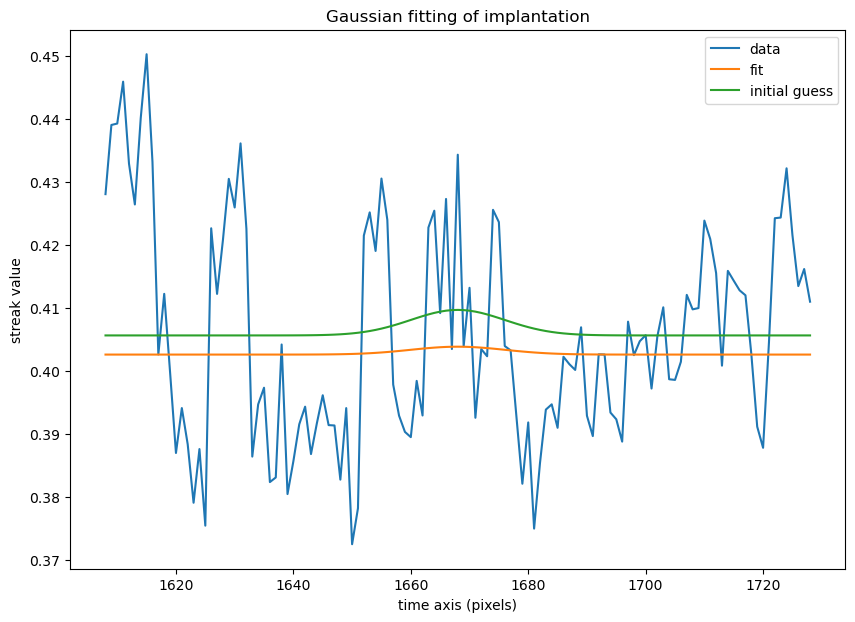

In [78]:
plot_it_out(4, transient_info_list, optimized_params_list, saved_tots)

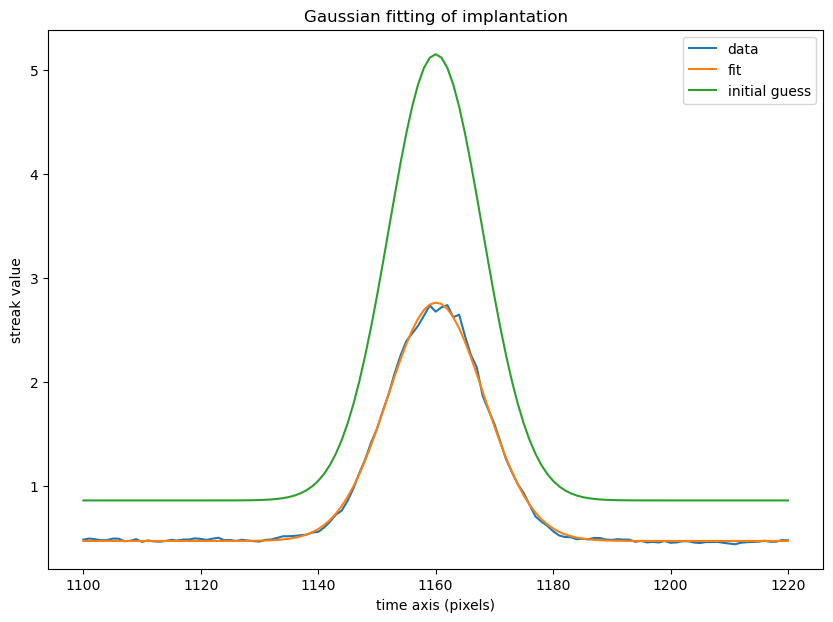

In [76]:
plot_it_out(2, transient_info_list, optimized_params_list, saved_tots)

In [181]:
len(transient_info_list)

16

In [ ]:
def calculate_how_good(transient_info_list, optimized_params_list):
    for index in range(len(transient_info_list)):
        M_guess, A_guess, sig_guess = transient_info_list[index][1:]
        (
            optimized_M,
            optimized_sig,
            optimized_A,
            optimized_streak_val,
        ) = optimized_params_list[index][:4]

In [ ]:
# i can figure out the streak thing if i come up with some candidates

In [ ]:
# whAT did i mean by that
# `b

In [ ]:
df_lessthan13 = pd.read_csv(
    "/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/df_lessthan13"
)